# Segmentação de uma pluma de fumaça com o Segment Anything Model 2 (SAM 2)

**Disciplina:** Modelagem Computacional  
**Modelo:** SAM 2.1 (`facebook/sam2.1-hiera-small`), utilizado por meio da biblioteca Hugging Face Transformers  
**Imagem analisada:** `ImagemPluma.webp` (984 × 738 pixels)

## 1. Objetivo

Segmentar uma pluma de fumaça em uma fotografia utilizando o SAM 2, avaliar criticamente a máscara obtida e aprimorar o procedimento por meio da escolha dos prompts, do código e da apresentação dos resultados. A segmentação automática pode incluir regiões que não pertencem à pluma, como céu, nuvens, vegetação e edificações; por isso, as melhorias adotadas são justificadas a partir de critérios qualitativos e quantitativos.

## 2. Metodologia

1. Segmentação inicial (*baseline*) com um único ponto positivo.
2. Avaliação da máscara quanto a três critérios: cobertura da pluma, inclusão de regiões que não pertencem a ela e omissão de partes da fumaça.
3. Comparação de cinco configurações de prompt (caixa delimitadora, pontos positivos e pontos negativos).
4. Análise das características da imagem que dificultam a segmentação: iluminação, contraste e semelhança entre fumaça e nuvens.
5. Pós-processamento morfológico e apresentação da máscara final.

## 3. Configuração do ambiente

In [1]:
!pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 31.7 MB/s eta 0:00:00


In [2]:
import numpy as np
import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from scipy import ndimage as ndi
from transformers import Sam2Processor, Sam2Model

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "facebook/sam2.1-hiera-small"

processor = Sam2Processor.from_pretrained(model_id)
model = Sam2Model.from_pretrained(model_id).to(device)
model.eval()

print("Dispositivo de execução:", device)

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  184MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

Dispositivo de execução: cpu


## 4. Carregamento da imagem

In [3]:
from google.colab import files

uploaded = files.upload()
imagem_path = next(iter(uploaded))

image = Image.open(imagem_path).convert("RGB")
image_np = np.array(image)
H, W = image_np.shape[:2]
print("Arquivo:", imagem_path, "| Dimensões (largura x altura):", W, "x", H)

Saving ImagemPluma.webp to ImagemPluma.webp
Arquivo: ImagemPluma.webp | Dimensões (largura x altura): 984 x 738


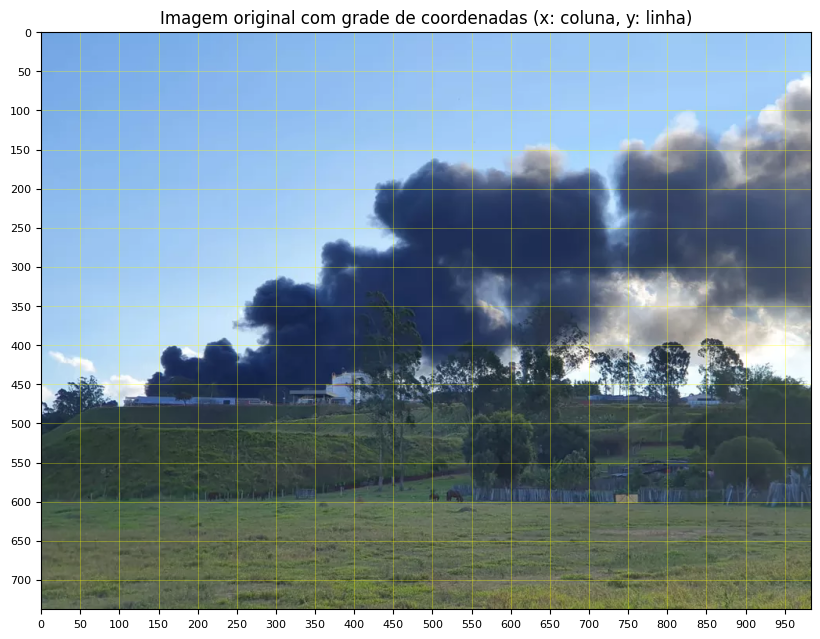

In [4]:
# Visualização com grade de coordenadas (em pixels), utilizada na definição dos prompts
fig, ax = plt.subplots(figsize=(10, 10 * H / W))
ax.imshow(image_np)
ax.set_xticks(np.arange(0, W, max(50, (W // 10) // 50 * 50)))
ax.set_yticks(np.arange(0, H, max(50, (H // 10) // 50 * 50)))
ax.grid(color="yellow", alpha=0.35, linewidth=0.6)
ax.tick_params(labelsize=8)
ax.set_title("Imagem original com grade de coordenadas (x: coluna, y: linha)")
plt.show()

## 5. Funções auxiliares

In [5]:
def segmentar(box=None, pos=(), neg=(), multimask=False, img=None):
    """Executa o SAM 2 com os prompts especificados.

    box: caixa delimitadora (x1, y1, x2, y2)
    pos: pontos positivos [(x, y), ...]
    neg: pontos negativos [(x, y), ...]
    multimask: se verdadeiro, retorna três hipóteses de máscara
    img: imagem PIL alternativa (por exemplo, com contraste realçado)

    Retorna (máscaras booleanas [n, H, W], pontuações estimadas pelo modelo [n]).
    """
    args = dict(images=image if img is None else img, return_tensors="pt")
    if box is not None:
        args["input_boxes"] = [[list(map(float, box))]]
    pts = [list(map(float, p)) for p in list(pos) + list(neg)]
    if pts:
        args["input_points"] = [[pts]]
        args["input_labels"] = [[[1] * len(pos) + [0] * len(neg)]]
    if not pts and box is None:
        raise ValueError("É necessário fornecer ao menos uma caixa ou um ponto.")

    inputs = processor(**args).to(device)
    with torch.no_grad():
        out = model(**inputs, multimask_output=multimask)

    masks = processor.post_process_masks(out.pred_masks.cpu(), inputs["original_sizes"])[0]
    masks = masks[0].numpy() > 0
    if hasattr(out, "iou_scores"):
        scores = out.iou_scores.detach().cpu().numpy().reshape(-1)
    else:
        scores = np.full(len(masks), np.nan)
    return masks, scores


def contorno(mask, cor=(0, 255, 255), esp=3):
    """Retorna a imagem original com o contorno da máscara desenhado."""
    vis = image_np.copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(vis, cnts, -1, cor, esp)
    return vis


def mostrar_lado_a_lado(mask, titulo="", box=None, pos=(), neg=(), salvar=None):
    """Apresenta lado a lado: imagem original, máscara binária e máscara sobreposta."""
    fig, axs = plt.subplots(1, 3, figsize=(18, 6.5))

    axs[0].imshow(image_np)
    axs[0].set_title("Imagem original")

    axs[1].imshow(mask, cmap="gray")
    axs[1].set_title(f"Máscara binária ({100 * mask.mean():.1f}% da imagem)")

    sobre = image_np.copy().astype(float)
    cor = np.array([255, 40, 40], dtype=float)
    sobre[mask] = 0.5 * sobre[mask] + 0.5 * cor
    axs[2].imshow(sobre.astype(np.uint8))
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    for c in cnts:
        axs[2].plot(c[:, 0, 0], c[:, 0, 1], color="cyan", linewidth=1.2)
    axs[2].set_title("Máscara sobreposta à imagem")

    if box is not None:
        x1, y1, x2, y2 = box
        axs[2].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                           linewidth=2, edgecolor="yellow", facecolor="none"))
    for x, y in pos:
        axs[2].scatter(x, y, c="lime", marker="*", s=220, edgecolors="black", linewidths=0.8)
    for x, y in neg:
        axs[2].scatter(x, y, c="red", marker="X", s=140, edgecolors="white", linewidths=0.8)

    for a in axs:
        a.axis("off")
    if titulo:
        fig.suptitle(titulo, fontsize=15)
    plt.tight_layout()
    if salvar:
        plt.savefig(salvar, dpi=150, bbox_inches="tight")
    plt.show()

## 6. Segmentação inicial (*baseline*)

A primeira segmentação utiliza um único ponto positivo, posicionado no núcleo escuro da massa central da pluma. Foi habilitada a geração de três hipóteses de máscara (`multimask_output=True`), que correspondem a diferentes níveis de abrangência (parte do objeto, objeto, conjunto). Adota-se como *baseline* a hipótese de maior pontuação estimada pelo modelo.

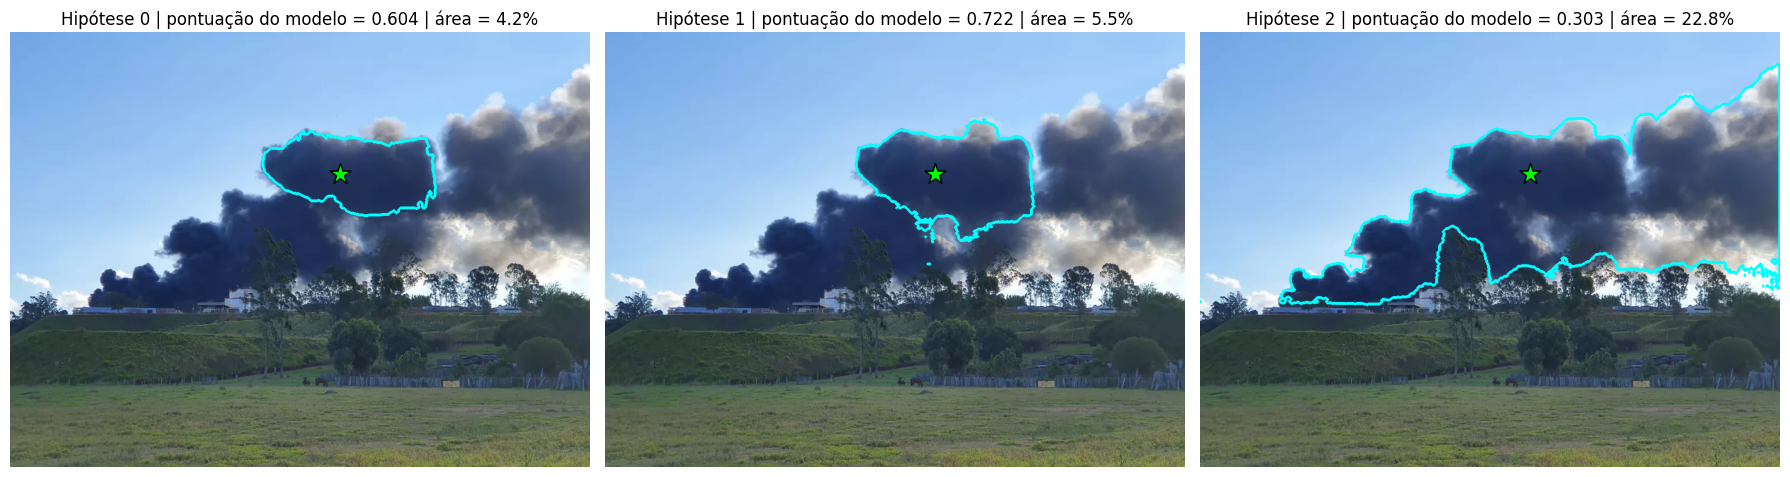

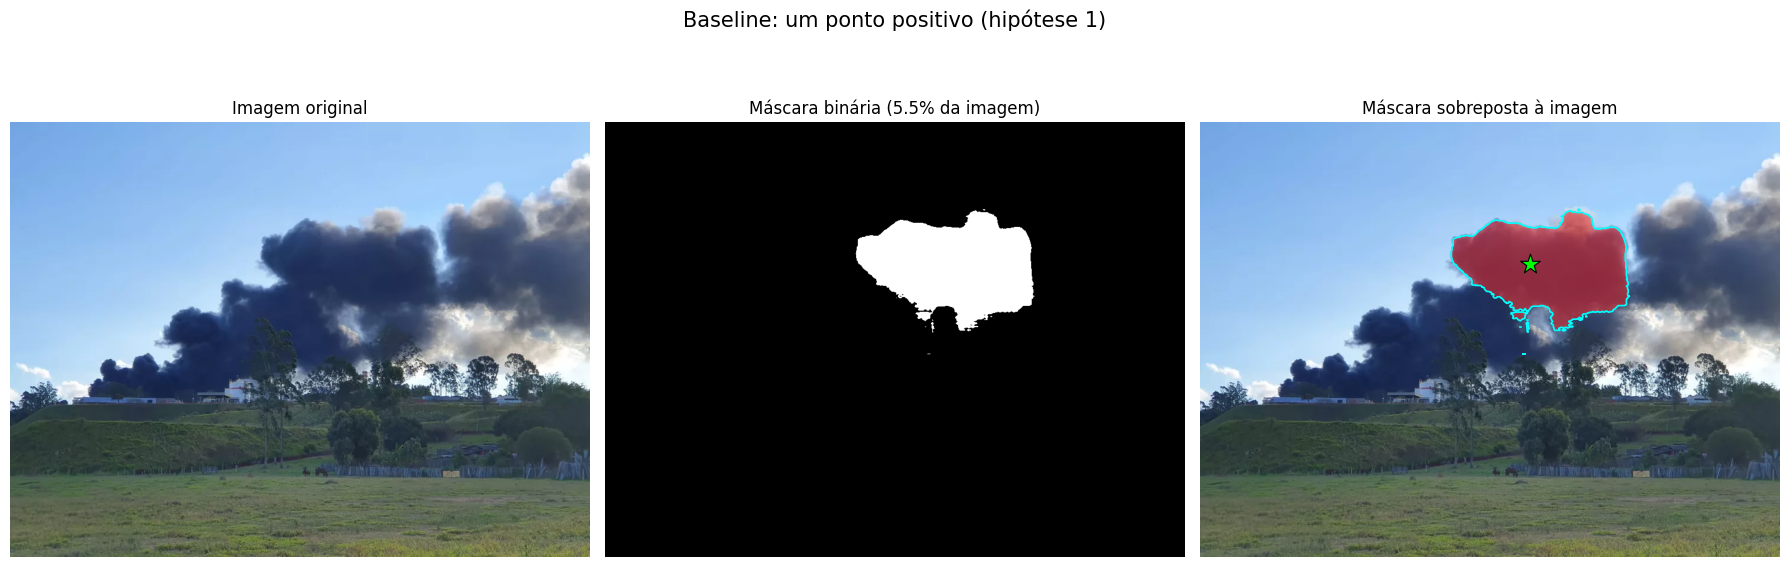

In [6]:
ponto_baseline = (560, 240)   # núcleo escuro da massa central

masks_b, scores_b = segmentar(pos=[ponto_baseline], multimask=True)

fig, axs = plt.subplots(1, len(masks_b), figsize=(6 * len(masks_b), 6))
for i, (m, s) in enumerate(zip(masks_b, scores_b)):
    axs[i].imshow(contorno(m))
    axs[i].scatter(*ponto_baseline, c="lime", marker="*", s=250, edgecolors="black")
    axs[i].set_title(f"Hipótese {i} | pontuação do modelo = {s:.3f} | área = {100*m.mean():.1f}%")
    axs[i].axis("off")
plt.tight_layout()
plt.show()

i_best = int(np.nanargmax(scores_b))
mask_baseline = masks_b[i_best]
mostrar_lado_a_lado(mask_baseline, f"Baseline: um ponto positivo (hipótese {i_best})", pos=[ponto_baseline])

### 6.1 Avaliação do baseline

A máscara é avaliada segundo três perguntas:

1. **A máscara cobre a pluma?** Verifica-se se as três massas de fumaça (base à esquerda, massa central e massa à direita) estão contidas na máscara.
2. **Inclui regiões que não pertencem à pluma?** Verifica-se a invasão de céu, nuvens claras, árvores e edificação.
3. **Deixa partes da fumaça de fora?** Verifica-se a omissão de bordas difusas, trechos acinzentados no topo e porções iluminadas.

**Hipóteses:** (i) um único ponto tende a produzir uma máscara limitada à massa em que foi posicionado, omitindo as demais massas de fumaça; (ii) as bordas translúcidas, mais claras e de baixo contraste com o céu, tendem a ser omitidas; (iii) a região em que a fumaça é iluminada pelo sol e se confunde com nuvens tende a ser incluída ou excluída de forma incorreta.

## 7. Configurações de prompt

Foram testadas cinco configurações, variando-se um elemento por vez para isolar o efeito de cada prompt:

| Configuração | Prompt | Aspecto avaliado |
|---|---|---|
| A | Caixa delimitadora | Capacidade da caixa de delimitar a pluma isoladamente |
| B | Caixa + pontos positivos | Recuperação de trechos de fumaça omitidos |
| C | Caixa + pontos positivos + pontos negativos | Exclusão de céu, nuvens, vegetação e edificação |
| D | Pontos positivos + pontos negativos (sem caixa) | Dispensabilidade da caixa |
| E | Configuração C aplicada à imagem com contraste realçado (CLAHE) | Efeito do realce de contraste sobre a segmentação |

A caixa abrange toda a pluma, incluindo sua base parcialmente oculta pela vegetação. Os pontos positivos foram posicionados sobre as três massas de fumaça e sobre o topo acinzentado. Os pontos negativos foram posicionados sobre o céu, a nuvem pequena à esquerda, a edificação branca, uma árvore sobreposta à pluma, o pasto e a região de nuvem clara à direita. Essa última região apresenta ambiguidade (nuvem ou fumaça iluminada por trás) e foi tratada como nuvem.

In [7]:
# Caixa delimitadora em torno da pluma (x1, y1, x2, y2)
caixa = (130, 55, 984, 482)

# Pontos positivos (sobre a fumaça): massa central, topo acinzentado, massa à direita, base à esquerda
positivos = [(560, 240), (640, 168), (850, 200), (330, 375), (200, 438)]

# Pontos negativos (fora da fumaça)
negativos = [(330, 150),   # céu azul no interior da caixa
             (600, 70),    # céu azul no topo
             (60, 425),    # nuvem pequena à esquerda
             (395, 458),   # edificação branca
             (447, 400),   # árvore à frente da pluma
             (880, 385),   # nuvem clara iluminada (região ambígua, tratada como nuvem)
             (400, 650)]   # pasto

# Imagem com contraste realçado (CLAHE aplicado ao canal L do espaço Lab), usada na configuração E
_lab = cv2.cvtColor(image_np, cv2.COLOR_RGB2LAB)
_lab[..., 0] = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(_lab[..., 0])
image_clahe = Image.fromarray(cv2.cvtColor(_lab, cv2.COLOR_LAB2RGB))

configs = {
    "A: só caixa":                      dict(box=caixa),
    "B: caixa + pontos +":              dict(box=caixa, pos=positivos),
    "C: caixa + pontos + e −":          dict(box=caixa, pos=positivos, neg=negativos),
    "D: só pontos + e −":               dict(pos=positivos, neg=negativos),
    "E: config C + contraste (CLAHE)":  dict(box=caixa, pos=positivos, neg=negativos, img=image_clahe),
}

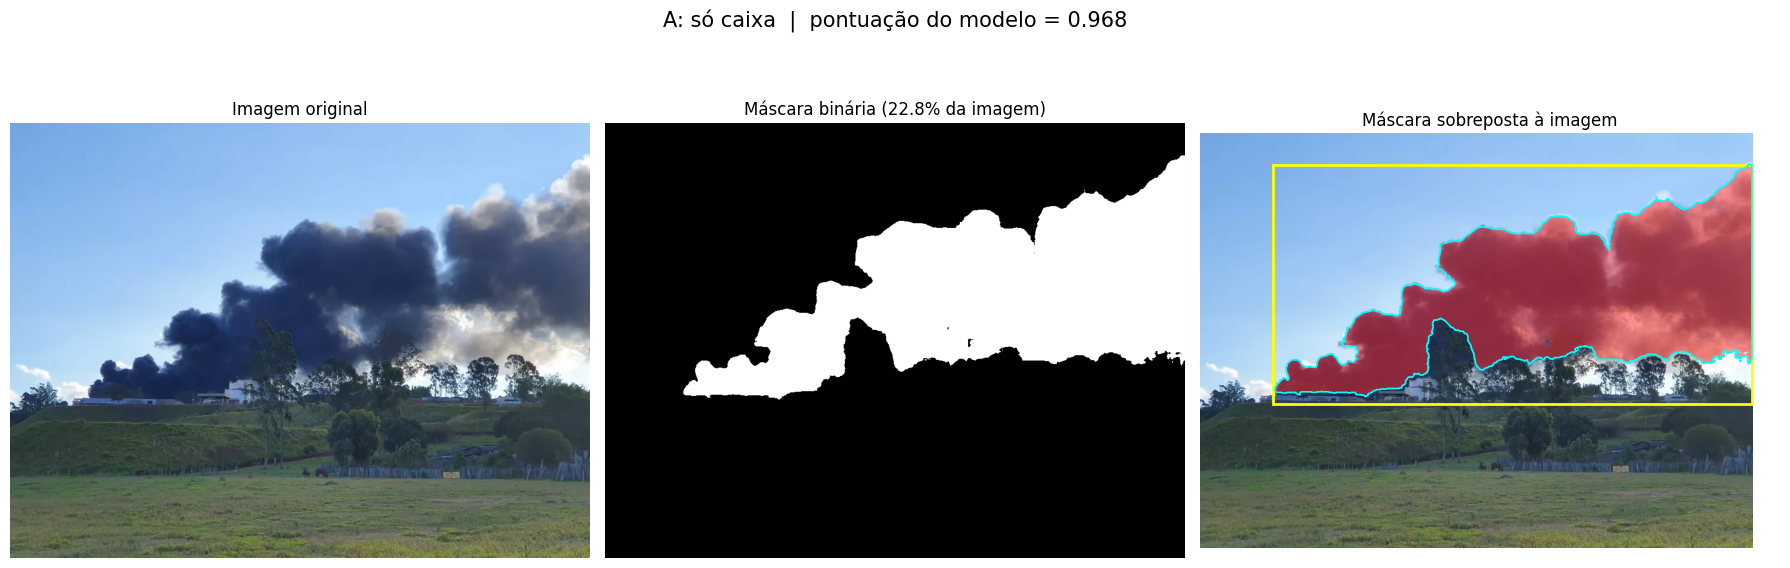

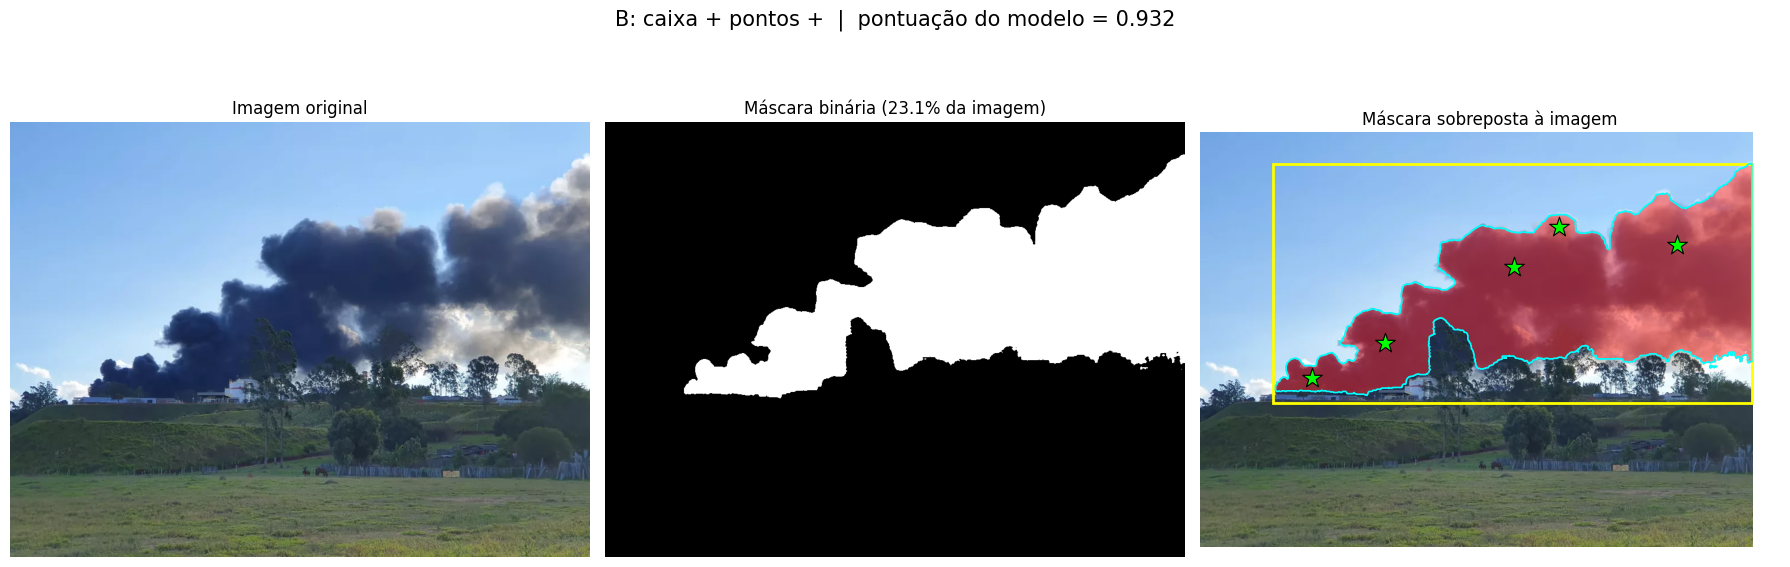

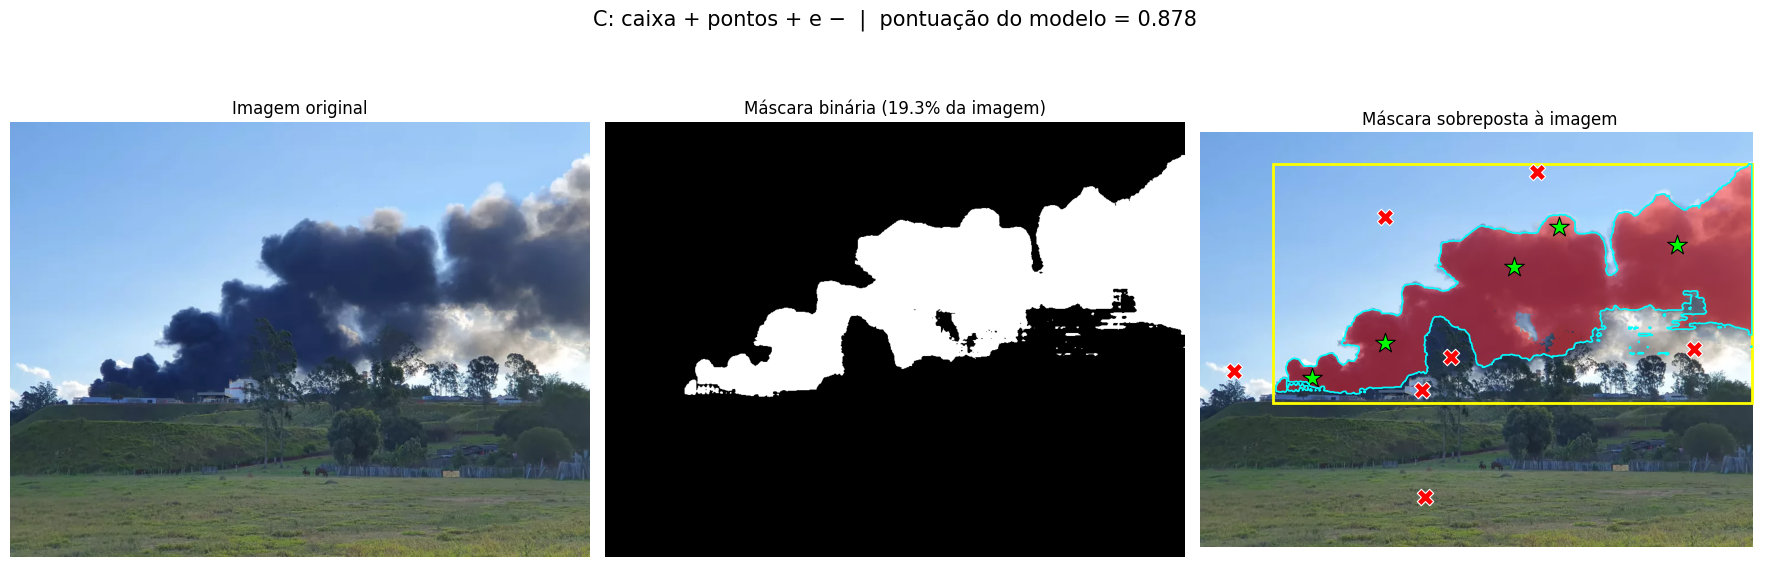

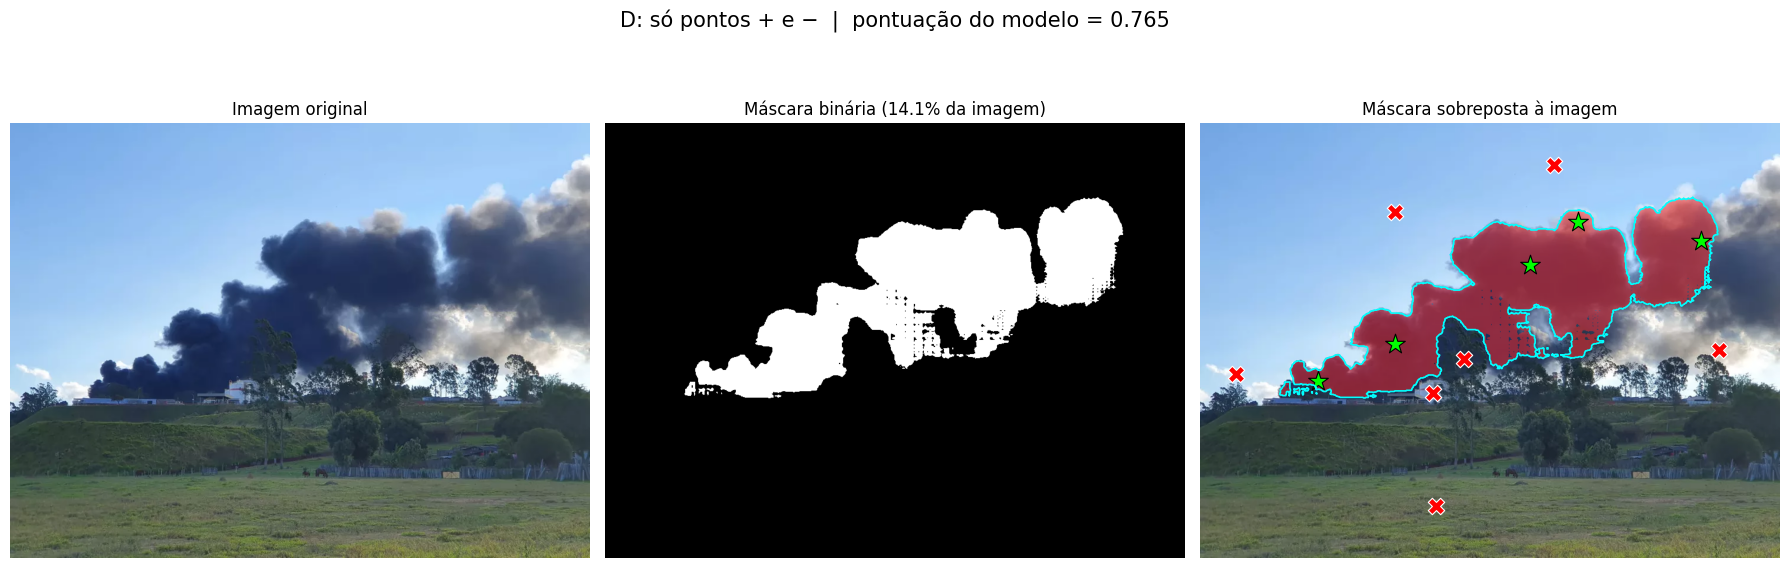

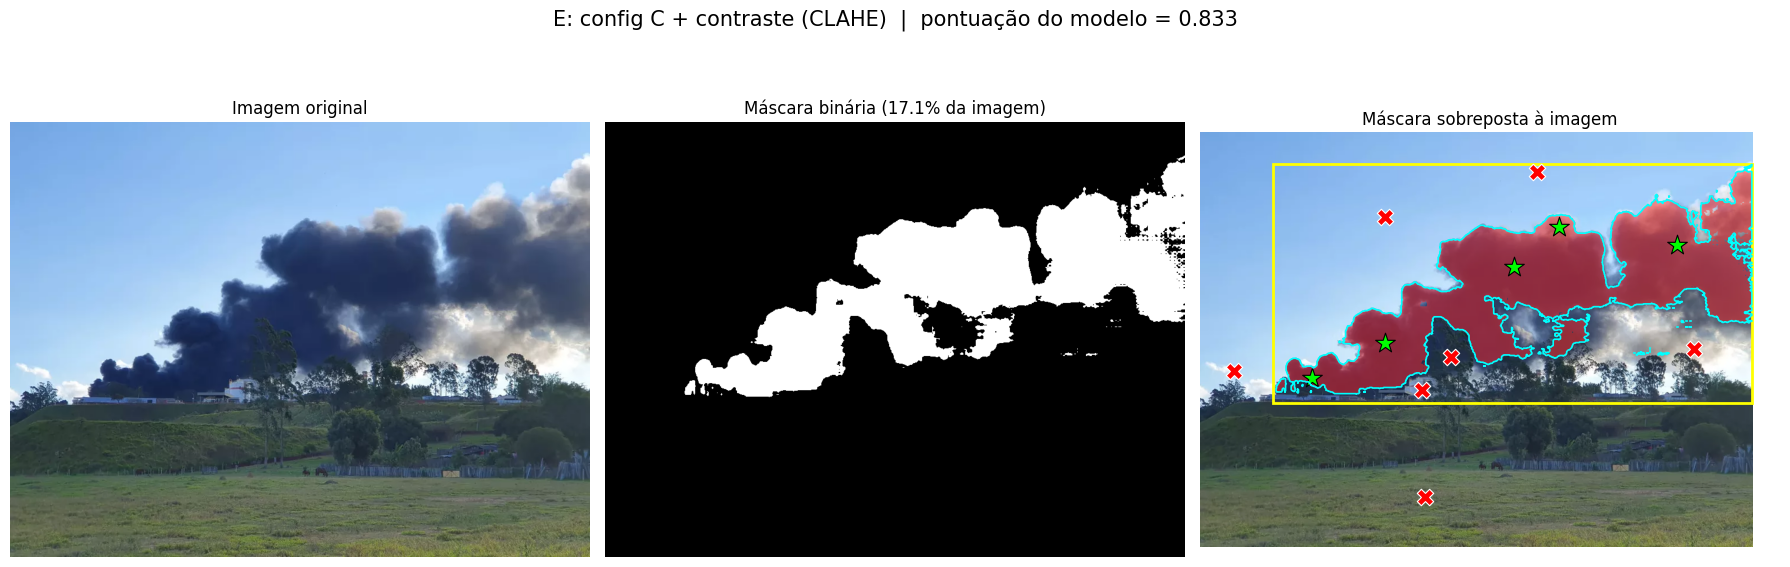

In [8]:
resultados = {}
for nome, cfg in configs.items():
    masks, scores = segmentar(**cfg, multimask=False)
    resultados[nome] = dict(mask=masks[0], score=float(scores[0]), cfg=cfg)
    mostrar_lado_a_lado(masks[0], f"{nome}  |  pontuação do modelo = {scores[0]:.3f}",
                        box=cfg.get("box"), pos=cfg.get("pos", ()), neg=cfg.get("neg", ()))

### 7.1 Comparação quantitativa

São calculados, para cada configuração:

- **Área** da máscara em relação à imagem;
- **IoU** (interseção sobre união) em relação ao *baseline* e entre as configurações, que mede o quanto cada prompt alterou o resultado (1 indica máscaras idênticas);
- **Percentual da máscara em regiões que não pertencem à pluma** (céu, pasto, edificação), definidas por caixas de referência. Esse valor funciona como indicador de falsos positivos, complementar à pontuação do modelo, que expressa a confiança do SAM e não a qualidade real da segmentação.

In [9]:
# Regiões de referência que não contêm fumaça (x1, y1, x2, y2)
regioes_proibidas = {
    "céu":    (20, 100, 300, 300),
    "pasto":  (0, 500, 984, 738),
    "prédio": (360, 430, 425, 480),
}

def iou(a, b):
    u = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / u if u else np.nan

def frac_em_regiao(mask, box):
    x1, y1, x2, y2 = box
    return mask[y1:y2, x1:x2].sum() / max(mask.sum(), 1)

nomes = list(resultados)
linhas = []
for n in nomes:
    m = resultados[n]["mask"]
    linha = {"config": n,
             "pontuação do modelo": round(resultados[n]["score"], 3),
             "área (% da imagem)": round(100 * m.mean(), 2),
             "IoU vs baseline": round(iou(m, mask_baseline), 3)}
    for rn, rb in regioes_proibidas.items():
        linha[f"% da máscara em '{rn}'"] = round(100 * frac_em_regiao(m, rb), 2)
    linhas.append(linha)
tabela = pd.DataFrame(linhas).set_index("config")
display(tabela)

iou_mat = pd.DataFrame([[iou(resultados[a]["mask"], resultados[b]["mask"]) for b in nomes] for a in nomes],
                       index=nomes, columns=nomes).round(3)
print("\nIoU entre as configurações:")
display(iou_mat)

,pontuação do modelo,área (% da imagem),IoU vs baseline,% da máscara em 'céu',% da máscara em 'pasto',% da máscara em 'prédio'
config,,,,,,
A: só caixa,0.968,22.80,0.243,0.0,0.0,0.13
B: caixa + pontos +,0.932,23.10,0.240,0.0,0.0,0.17
C: caixa + pontos + e −,0.878,19.33,0.286,0.0,0.0,0.12
D: só pontos + e −,0.765,14.14,0.386,0.0,0.0,0.18
E: config C + contraste (CLAHE),0.833,17.09,0.297,0.0,0.0,0.16



IoU entre as configurações:


,A: só caixa,B: caixa + pontos +,C: caixa + pontos + e −,D: só pontos + e −,E: config C + contraste (CLAHE)
A: só caixa,1.000,0.985,0.843,0.618,0.743
B: caixa + pontos +,0.985,1.000,0.836,0.611,0.737
C: caixa + pontos + e −,0.843,0.836,1.000,0.727,0.865
D: só pontos + e −,0.618,0.611,0.727,1.000,0.755
E: config C + contraste (CLAHE),0.743,0.737,0.865,0.755,1.000


### 7.2 Análise das configurações

**Hipóteses:**

- **A (só caixa):** a caixa delimita a região de interesse, mas, por conter céu, nuvens, árvores e edificação, o modelo pode incluir objetos internos à caixa que não são fumaça.
- **B (caixa + pontos positivos):** os pontos positivos sobre as demais massas e sobre o topo acinzentado devem aumentar a cobertura da pluma, ao custo de possível aumento da área incorreta.
- **C (com pontos negativos):** os pontos negativos devem reduzir a invasão de céu, nuvem, edificação e vegetação. Em contrapartida, pontos negativos próximos à fumaça translúcida podem gerar recortes indesejados no interior ou nas bordas da pluma.
- **D (sem caixa):** na ausência da caixa, a máscara tende a ser mais sensível à posição dos pontos e menos delimitada espacialmente.
- **E (CLAHE):** o realce de contraste pode favorecer a separação entre fumaça e fundo nas bordas difusas, mas também pode acentuar texturas de nuvens e vegetação.

**Observações:** *(a serem completadas com base nos resultados da execução, citando a tabela acima e identificando a configuração de melhor desempenho)*

## 8. Características da imagem que dificultam a segmentação

A análise é realizada sobre a máscara da configuração selecionada como a de melhor desempenho. Três fatores são quantificados no espaço de cor CIELAB:

| Fator | Medida |
|---|---|
| **Iluminação** | Brilho médio (L*) no interior da pluma, no entorno e na imagem inteira; desvio-padrão do brilho na pluma; percentual de pixels saturados (L* > 90) |
| **Contraste** | Diferença de cor ΔE entre a pluma e um anel de 30 px ao seu redor; razão entre o gradiente médio na borda da máscara e o gradiente médio da imagem |
| **Semelhança com nuvem e céu** | ΔE entre as cores médias e sobreposição dos histogramas de brilho entre a pluma e regiões de referência de céu e de nuvem |

Valores baixos de ΔE (inferiores a aproximadamente 10), razão de gradiente inferior a 1 e alta sobreposição de histogramas indicam maior dificuldade de separação.

In [10]:
MELHOR = "C: caixa + pontos + e −"   # configuração selecionada para a análise

# Regiões de referência sem fumaça
ref_ceu   = (20, 100, 300, 300)    # céu limpo à esquerda
ref_nuvem = (760, 335, 960, 410)   # nuvem clara iluminada à direita

mask_m = resultados[MELHOR]["mask"]

In [11]:
# Conversão de cor
lab_cv = cv2.cvtColor(image_np, cv2.COLOR_RGB2LAB).astype(np.float32)
L = lab_cv[..., 0] * 100.0 / 255.0
A = lab_cv[..., 1] - 128.0
B = lab_cv[..., 2] - 128.0
LAB = np.stack([L, A, B], axis=-1)
gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY).astype(np.float32)

def media_lab(m):
    return LAB[m].mean(axis=0)

def delta_e(c1, c2):
    return float(np.linalg.norm(c1 - c2))

def anel(mask, raio=30):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * raio + 1, 2 * raio + 1))
    dil = cv2.dilate(mask.astype(np.uint8), k).astype(bool)
    return dil & ~mask

def mascara_caixa(box):
    m = np.zeros((H, W), bool)
    x1, y1, x2, y2 = box
    m[y1:y2, x1:x2] = True
    return m

def sobreposicao_hist(m1, m2, bins=32):
    h1 = cv2.calcHist([L.astype(np.float32)], [0], m1.astype(np.uint8), [bins], [0, 100])
    h2 = cv2.calcHist([L.astype(np.float32)], [0], m2.astype(np.uint8), [bins], [0, 100])
    cv2.normalize(h1, h1, 1, 0, cv2.NORM_L1)
    cv2.normalize(h2, h2, 1, 0, cv2.NORM_L1)
    return float(np.minimum(h1, h2).sum())   # 0: distribuições distintas; 1: idênticas

# Iluminação
anel_m = anel(mask_m)
print("=== ILUMINAÇÃO ===")
print(f"Brilho médio da imagem inteira (L*)        : {L.mean():.1f}")
print(f"Brilho médio no interior da pluma (L*)     : {L[mask_m].mean():.1f}")
print(f"Brilho médio no anel ao redor (L*)         : {L[anel_m].mean():.1f}")
print(f"Desvio-padrão do brilho na pluma           : {L[mask_m].std():.1f}  (valores altos indicam iluminação irregular)")
print(f"Pixels muito claros (L* > 90) na imagem    : {100*(L>90).mean():.1f}%")

# Contraste
cor_pluma = media_lab(mask_m)
cor_anel = media_lab(anel_m)
gray_s = cv2.GaussianBlur(gray, (5, 5), 0)
grad = np.hypot(cv2.Sobel(gray_s, cv2.CV_32F, 1, 0), cv2.Sobel(gray_s, cv2.CV_32F, 0, 1))
borda = mask_m & ~cv2.erode(mask_m.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)

print("\n=== CONTRASTE ===")
print(f"ΔE entre pluma e anel ao redor             : {delta_e(cor_pluma, cor_anel):.1f}")
print(f"Gradiente médio na borda da máscara        : {grad[borda].mean():.1f}")
print(f"Gradiente médio da imagem inteira          : {grad.mean():.1f}")
print(f"Razão borda/imagem                         : {grad[borda].mean()/grad.mean():.2f}  (valores < 1 indicam borda difusa)")

# Semelhança com céu e nuvem
print("\n=== SEMELHANÇA COM CÉU E NUVEM ===")
for nome, ref in [("céu", ref_ceu), ("nuvem", ref_nuvem)]:
    mr = mascara_caixa(ref)
    print(f"{nome:6s}: ΔE em relação à pluma = {delta_e(cor_pluma, media_lab(mr)):5.1f} | "
          f"sobreposição do histograma de brilho = {sobreposicao_hist(mask_m, mr):.2f}")

=== ILUMINAÇÃO ===
Brilho médio da imagem inteira (L*)        : 51.8
Brilho médio no interior da pluma (L*)     : 34.5
Brilho médio no anel ao redor (L*)         : 64.6
Desvio-padrão do brilho na pluma           : 17.1  (valores altos indicam iluminação irregular)
Pixels muito claros (L* > 90) na imagem    : 1.7%

=== CONTRASTE ===
ΔE entre pluma e anel ao redor             : 31.5
Gradiente médio na borda da máscara        : 55.7
Gradiente médio da imagem inteira          : 18.0
Razão borda/imagem                         : 3.10  (valores < 1 indicam borda difusa)

=== SEMELHANÇA COM CÉU E NUVEM ===
céu   : ΔE em relação à pluma =  43.3 | sobreposição do histograma de brilho = 0.06
nuvem : ΔE em relação à pluma =  42.0 | sobreposição do histograma de brilho = 0.29


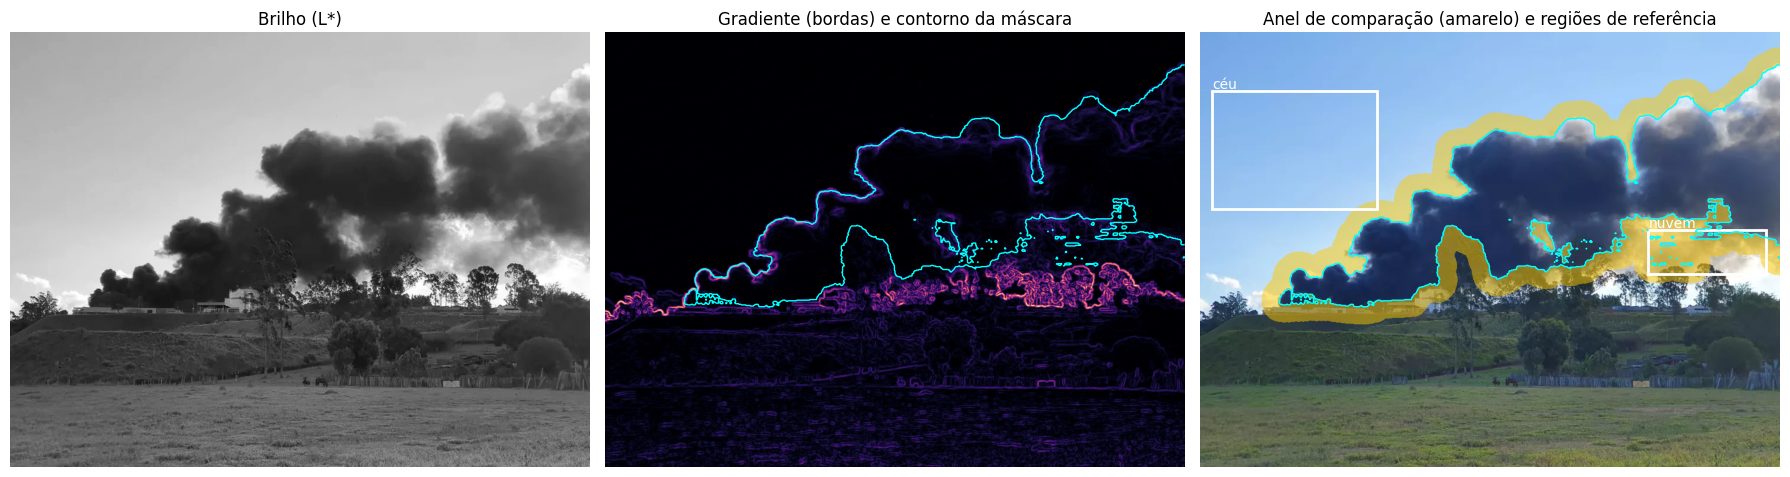

In [12]:
# Mapas de apoio à interpretação: brilho, gradiente e anel de comparação
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(L, cmap="gray")
axs[0].set_title("Brilho (L*)")
axs[1].imshow(grad, cmap="magma")
axs[1].contour(mask_m, levels=[0.5], colors="cyan", linewidths=1)
axs[1].set_title("Gradiente (bordas) e contorno da máscara")
vis = image_np.copy()
vis[anel_m] = (0.5 * vis[anel_m] + 0.5 * np.array([255, 200, 0])).astype(np.uint8)
axs[2].imshow(vis)
axs[2].contour(mask_m, levels=[0.5], colors="cyan", linewidths=1)
axs[2].set_title("Anel de comparação (amarelo) e regiões de referência")
for nome, box in [("céu", ref_ceu), ("nuvem", ref_nuvem)]:
    x1, y1, x2, y2 = box
    axs[2].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="white", facecolor="none"))
    axs[2].text(x1, y1 - 5, nome, color="white")
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()

### 8.1 Interpretação

**Hipóteses, a partir da inspeção visual da imagem:**

- **Iluminação:** a pluma é predominantemente escura, mas apresenta bordas e porções superiores acinzentadas e, à direita, uma região iluminada por contraluz. Essa heterogeneidade de brilho tende a fragmentar a máscara e a levar o modelo a interromper a segmentação nas áreas mais claras.
- **Contraste:** o núcleo escuro contrasta fortemente com o céu azul, o que favorece a segmentação. As bordas translúcidas, porém, apresentam gradiente suave e baixa diferença de cor em relação ao fundo, o que tende a gerar bordas imprecisas.
- **Semelhança com nuvens:** na região à direita, a fumaça se mistura a nuvens claras iluminadas, com tons e texturas próximos. Espera-se menor ΔE e maior sobreposição de histogramas em relação à referência de nuvem do que em relação à de céu, o que explicaria a necessidade de pontos negativos e a maior incerteza nessa região.
- **Oclusão e outros fatores:** as árvores à frente da base da pluma e a edificação branca introduzem objetos com cores e bordas próprias dentro da caixa, favorecendo a inclusão indevida ou a fragmentação da máscara.

**Observações:** *(a serem completadas com os valores numéricos obtidos acima, confrontando-os com as hipóteses)*

## 9. Pós-processamento e máscara final

Mesmo com prompts adequados, a máscara pode conter ruídos. São aplicadas as seguintes operações, cada uma associada a um problema específico:

1. **Fechamento morfológico:** une fragmentos próximos pertencentes à mesma pluma.
2. **Preenchimento de buracos:** corrige falhas internas causadas por trechos mais claros ou por pontos negativos próximos à fumaça.
3. **Remoção de componentes pequenos:** elimina manchas isoladas de céu ou nuvem.
4. **Manutenção apenas dos componentes que contêm pontos positivos:** descarta regiões desconectadas da pluma.

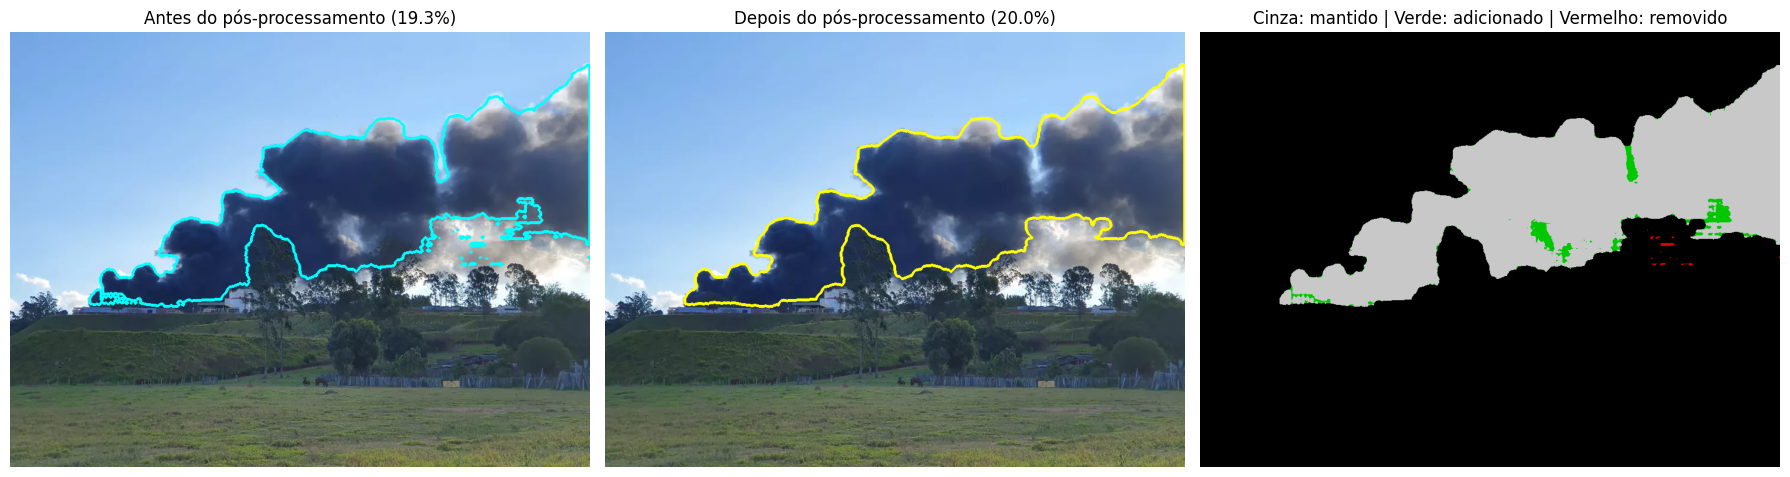

In [13]:
# Parâmetros do pós-processamento
RAIO_FECHAMENTO = 7          # raio do elemento estruturante, em pixels (0 desativa)
PREENCHER_BURACOS = True
AREA_MIN_FRAC = 0.02         # componentes com área inferior a 2% da maior são descartados (0 desativa)
SO_COMPONENTE_DOS_PONTOS = True

def posprocessar(mask, pontos_pos=()):
    m = mask.copy()
    if RAIO_FECHAMENTO > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * RAIO_FECHAMENTO + 1,) * 2)
        m = cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_CLOSE, k).astype(bool)
    if PREENCHER_BURACOS:
        m = ndi.binary_fill_holes(m)
    rot, n = ndi.label(m)
    if n > 1:
        areas = ndi.sum(m, rot, index=range(1, n + 1))
        manter = [i + 1 for i, a in enumerate(areas) if a >= AREA_MIN_FRAC * areas.max()]
        if SO_COMPONENTE_DOS_PONTOS and len(pontos_pos):
            com_ponto = {rot[int(y), int(x)] for x, y in pontos_pos if rot[int(y), int(x)] > 0}
            if com_ponto:
                manter = [i for i in manter if i in com_ponto]
        m = np.isin(rot, manter)
    return m

cfg_m = resultados[MELHOR]["cfg"]
mask_final = posprocessar(mask_m, cfg_m.get("pos", ()))

fig, axs = plt.subplots(1, 3, figsize=(18, 6.5))
axs[0].imshow(contorno(mask_m))
axs[0].set_title(f"Antes do pós-processamento ({100*mask_m.mean():.1f}%)")
axs[1].imshow(contorno(mask_final, (255, 255, 0)))
axs[1].set_title(f"Depois do pós-processamento ({100*mask_final.mean():.1f}%)")
dif = np.zeros((H, W, 3), np.uint8)
dif[mask_m & mask_final] = (200, 200, 200)
dif[~mask_m & mask_final] = (0, 200, 0)
dif[mask_m & ~mask_final] = (220, 0, 0)
axs[2].imshow(dif)
axs[2].set_title("Cinza: mantido | Verde: adicionado | Vermelho: removido")
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()

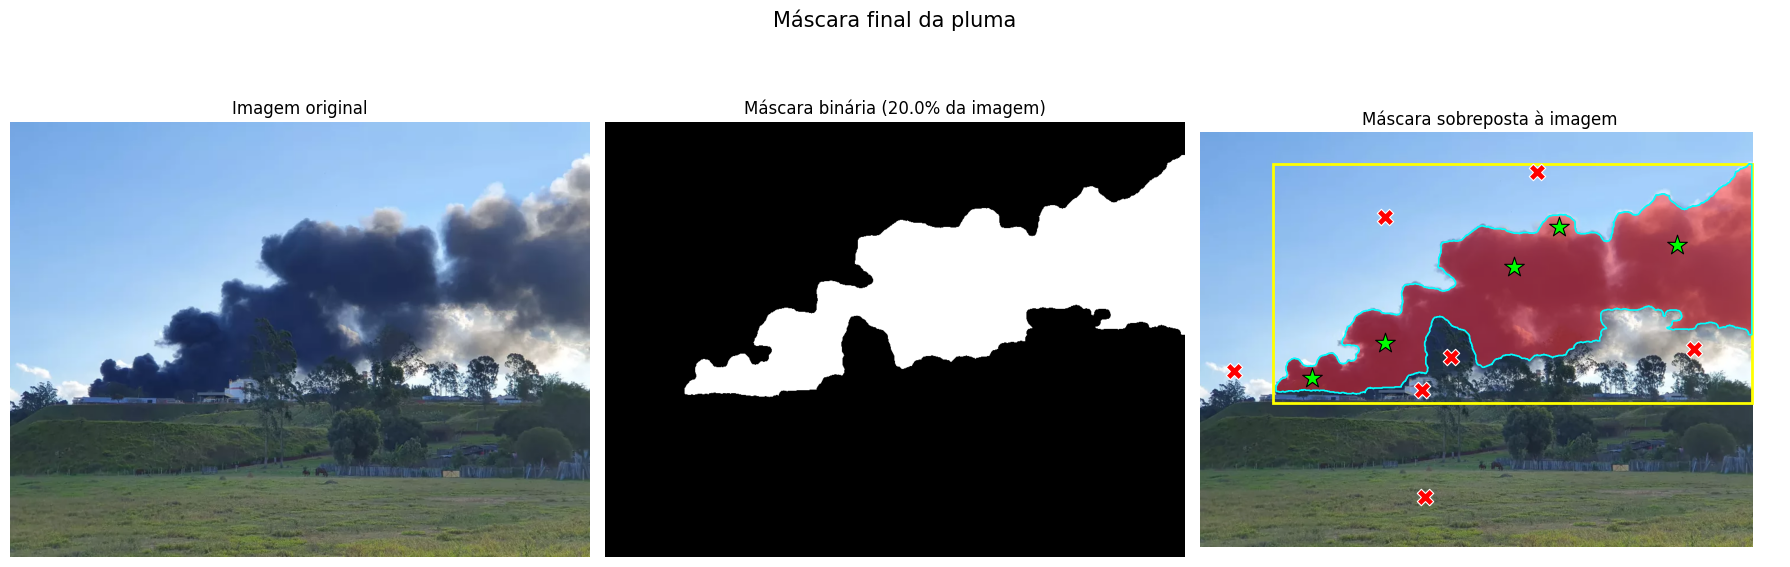

Arquivos gerados: resultado_final.png e mascara_final.png
Área final da pluma: 145261 px (20.0% da imagem)


In [14]:
# Apresentação final: imagem original, máscara binária e máscara sobreposta
mostrar_lado_a_lado(mask_final, "Máscara final da pluma",
                    box=cfg_m.get("box"), pos=cfg_m.get("pos", ()), neg=cfg_m.get("neg", ()),
                    salvar="resultado_final.png")

Image.fromarray((mask_final * 255).astype(np.uint8)).save("mascara_final.png")
print("Arquivos gerados: resultado_final.png e mascara_final.png")
print(f"Área final da pluma: {mask_final.sum()} px ({100*mask_final.mean():.1f}% da imagem)")

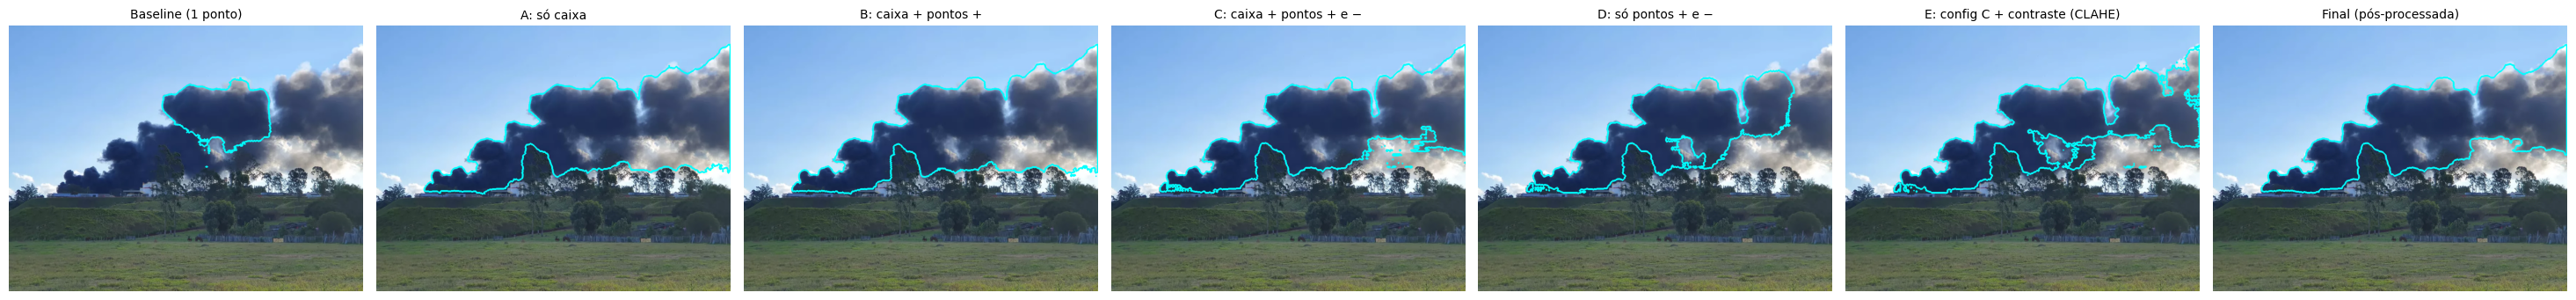

In [15]:
# Síntese comparativa de todas as etapas
painel = [("Baseline (1 ponto)", mask_baseline)] + [(n, resultados[n]["mask"]) for n in resultados] + [("Final (pós-processada)", mask_final)]
fig, axs = plt.subplots(1, len(painel), figsize=(4.2 * len(painel), 5))
for a, (n, m) in zip(axs, painel):
    a.imshow(contorno(m, esp=4))
    a.set_title(n, fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.savefig("comparacao_configs.png", dpi=130, bbox_inches="tight")
plt.show()

## 10. Conclusões

### 10.1 Melhorias implementadas em relação ao notebook inicial

1. **Prompts:** substituição do ponto único por cinco configurações sistemáticas (caixa, pontos positivos, pontos negativos, ausência de caixa e realce de contraste), com variação de um elemento por vez, permitindo atribuir cada mudança de resultado a um prompt específico. Os pontos negativos foram posicionados sobre os elementos efetivamente suscetíveis a falsos positivos: céu, nuvens, edificação, vegetação e pasto.
2. **Código:** função única de segmentação parametrizada (caixa, pontos, imagem alternativa); substituição da interface interativa por coordenadas explícitas, o que torna o experimento reprodutível; uso das três hipóteses de máscara do SAM no *baseline*.
3. **Avaliação:** além da inspeção visual, uso de métricas objetivas (área, IoU entre configurações e percentual da máscara em regiões sem fumaça) e de medidas de iluminação, contraste e semelhança com nuvem e céu no espaço CIELAB.
4. **Apresentação da máscara:** painel lado a lado com imagem original, máscara binária e máscara sobreposta com contorno, caixa e pontos identificados por cor, além de painel comparativo de todas as etapas.
5. **Pós-processamento:** fechamento morfológico, preenchimento de buracos e remoção de componentes pequenos ou desconectados, com visualização das alterações realizadas.

### 10.2 Limitações

- A região de nuvem clara iluminada à direita é ambígua (nuvem ou fumaça iluminada por contraluz); a classificação adotada nos prompts é uma decisão do analista e afeta diretamente a área final.
- A ausência de uma máscara de referência (*ground truth*) impede o cálculo de métricas de acurácia como IoU ou F1 em relação à pluma real; a avaliação baseia-se em inspeção visual e em indicadores indiretos.
- O modelo utilizado é a versão `small`, de menor capacidade.